# A05 — Riesgo de tipos: DV01 por bucket, convexidad, carry, PCA y cobertura

**Objetivos:** DV01 paralelo y por cotización reconstruyendo las curvas; convexidad; *carry* y *roll-down*;
PCA de movimientos de curva; caso de la aseguradora que cubre su gap de duración.

**Fuentes:** Veronesi cap. 3–4 y 16; Schofield & Bowler cap. 3 y 6; Hull cap. 22. Datos sintéticos.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # notebooks/ -> repository root
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True

from derivlab.market import sample_market, bump_market
from derivlab.curves import build_curves, discount, shift_curve, zero_rate, make_curve, time_from, tenor_end
from derivlab.dates import spot_date, add_months, year_fraction, make_schedule
from derivlab.swaps import price_swap, par_swap_rate, estr_leg_pv
from derivlab.risk import bucket_dv01, parallel_dv01, pca, hedge_notionals

m = sample_market()
estr, eur = build_curves(m)
ref, spot = m["ref_date"], spot_date(m["ref_date"])

## 1. DV01 de un payer swap a 10 años sobre 50 M€

In [2]:
N, end10 = 50e6, add_months(spot, 120)
k10 = par_swap_rate(ref, spot, end10, N, estr, eur)
pv10 = lambda e, r: price_swap(ref, spot, end10, N, k10, e, r)["pv"]

par_dv01 = parallel_dv01(m, pv10)
zero_dv01 = pv10(shift_curve(estr, 1), shift_curve(eur, 1)) - pv10(estr, eur)
annuity = price_swap(ref, spot, end10, N, k10, estr, eur)["annuity"]
print(f"CASE 10y payer 50M: par-quote DV01 = {par_dv01:,.0f}; zero-rate DV01 = {zero_dv01:,.0f}; "
      f"rule N*A*1bp = {annuity * 1e-4:,.0f} EUR/bp")
buckets = bucket_dv01(m, pv10)
buckets[buckets.dv01.abs() > 1].round(0)

CASE 10y payer 50M: par-quote DV01 = 43,989; zero-rate DV01 = 44,758; rule N*A*1bp = 44,012 EUR/bp


,instrument,tenor,dv01
27,swap,10Y,44012.0


Todo el riesgo cae en el pilar de 10 años de la curva Euribor. La sensibilidad a las cotizaciones €STR es
prácticamente nula: si sube el €STR, la curva Euribor se recalibra para seguir repreciando los swaps cotizados,
y un swap a la par vale cero con cualquier curva de descuento. Fuera de la par sí aparece riesgo de descuento.

## 2. Convexidad

In [3]:
shifts = np.array([-200, -100, -50, 0, 50, 100, 200])
pvs = np.array([pv10(shift_curve(estr, s), shift_curve(eur, s)) for s in shifts])
lin = shifts * zero_dv01
conv = pd.DataFrame({"shift_bp": shifts, "pv": pvs, "linear": lin, "convexity_effect": pvs - lin})
print(conv.round(0).to_string(index=False))
print(f"CASE convexity effect at +/-200 bp: {conv.convexity_effect.iloc[-1]:,.0f} / {conv.convexity_effect.iloc[0]:,.0f} EUR")

 shift_bp         pv     linear  convexity_effect
     -200 -9874259.0 -8951553.0         -922706.0
     -100 -4699965.0 -4475776.0         -224189.0
      -50 -2293562.0 -2237888.0          -55674.0
        0       -0.0        0.0              -0.0
       50  2186117.0  2237888.0          -51772.0
      100  4269923.0  4475776.0         -205853.0
      200  8149924.0  8951553.0         -801629.0
CASE convexity effect at +/-200 bp: -801,629 / -922,706 EUR


## 3. *Carry* y *roll-down* de un receiver a 5 años en 3 meses

Escenario de curva estática: dentro de 3 meses, el tipo cero para cada plazo residual es el mismo que hoy.
El swap envejece y se valora en una parte más baja de la curva.

In [4]:
def static_curve(curve, horizon):
    """Curve at `horizon` with today's zero rates by time-to-maturity."""
    dates = [d for d in curve["dates"] if d > horizon]
    dfs = []
    for d in dates:
        tau = time_from(horizon, d)
        z = -np.log(discount(curve, curve["ref_date"] + (d - horizon))) / time_from(curve["ref_date"], curve["ref_date"] + (d - horizon))
        dfs.append(np.exp(-z * tau))
    return make_curve(horizon, dates, dfs, curve["name"])

end5 = add_months(spot, 60)
k5 = par_swap_rate(ref, spot, end5, N, estr, eur)
horizon = add_months(ref, 3)
first = make_schedule(spot, end5, 6)[0]
fix = {first["fixing_date"]: m["euribor6m_fixing"]}
pv_today = price_swap(ref, spot, end5, N, k5, estr, eur, side="receiver")["pv"]
pv_h = price_swap(horizon, spot, end5, N, k5, static_curve(estr, horizon), static_curve(eur, horizon),
                  side="receiver", fixings=fix)["pv"]
print(f"CASE receiver 5y 50M at {k5:.3%}: carry + roll-down over 3 months = {pv_h - pv_today:,.0f} EUR")

CASE receiver 5y 50M at 2.404%: carry + roll-down over 3 months = 76,875 EUR


## 4. PCA de movimientos de curva (datos sintéticos)

       PC1    PC2    PC3
1y   0.417  0.628 -0.506
2y   0.415  0.378  0.164
5y   0.407  0.052  0.533
10y  0.405 -0.174  0.407
20y  0.405 -0.397 -0.082
30y  0.401 -0.521 -0.511
CASE explained variance: PC1 79.9%, PC2 17.6%, PC3 2.1%


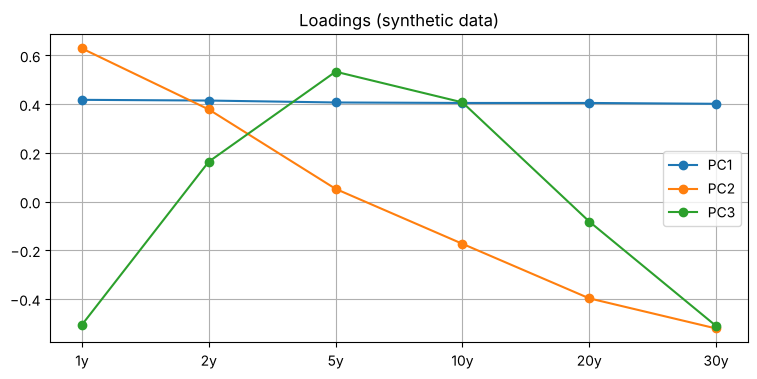

In [5]:
tenors = np.array([1, 2, 5, 10, 20, 30])
rng = np.random.default_rng(42)
n_days = 750
level = rng.normal(0, 4.0, n_days)
slope = rng.normal(0, 1.8, n_days)
curv = rng.normal(0, 0.8, n_days)
loading_level = np.ones(len(tenors))
loading_slope = (np.log(tenors) - np.log(tenors).mean()) / np.log(tenors).std()
loading_curv = -(loading_slope ** 2 - (loading_slope ** 2).mean())
changes = (np.outer(level, loading_level) + np.outer(slope, loading_slope) + np.outer(curv, loading_curv)
           + rng.normal(0, 0.4, (n_days, len(tenors))))
vals, vecs, ratio = pca(changes)
pcs = pd.DataFrame(vecs[:, :3], index=[f"{t}y" for t in tenors], columns=["PC1", "PC2", "PC3"])
print(pcs.round(3))
print(f"CASE explained variance: PC1 {ratio[0]:.1%}, PC2 {ratio[1]:.1%}, PC3 {ratio[2]:.1%}")
pcs.plot(marker="o", title="Loadings (synthetic data)"); plt.show()

Los porcentajes salen de cómo se generaron los datos; lo que importa es leer las formas: nivel (todos los plazos
en el mismo sentido), pendiente (cortos frente a largos) y curvatura (centro frente a extremos). Con datos reales
de swaps EUR, el primer componente suele explicar la gran mayoría de la varianza.

## 5. Caso: una aseguradora cubre su gap de duración

Activo: 500 M€ en tres bonos sin riesgo de crédito (cupones anuales 30/360). Pasivo: pagos anuales a 30 años
concentrados alrededor de 15 años. Todo se descuenta con €STR, así que el riesgo vive en los pilares OIS.
La cobertura usa OIS a 5, 10 y 20 años y se calcula por mínimos cuadrados sobre los buckets.

In [6]:
def bond_pv(e, notional, coupon, years):
    per = make_schedule(spot, add_months(spot, 12 * years), 12)
    pv = sum(notional * coupon * year_fraction(p["accrual_start"], p["accrual_end"], "30/360") * discount(e, p["pay_date"]) for p in per)
    return pv + notional * discount(e, per[-1]["pay_date"])

bonds = [(150e6, 0.022, 3), (200e6, 0.026, 7), (150e6, 0.029, 10)]
liab_years = np.arange(1, 31)
liab_flows = 32e6 * np.exp(-0.5 * ((liab_years - 15) / 7.0) ** 2)

def assets_pv(e, r=None):
    return sum(bond_pv(e, n, c, y) for n, c, y in bonds)

def liabilities_pv(e, r=None):
    return -sum(cf * discount(e, add_months(spot, 12 * int(y))) for y, cf in zip(liab_years, liab_flows))

def net_pv(e, r=None):
    return assets_pv(e) + liabilities_pv(e)

def ois_receiver(tenor_y, notional=1e6):
    end = add_months(spot, 12 * tenor_y)
    def pv(e, r=None):
        k = par_swap_ois[tenor_y]
        float_pv, ann = estr_leg_pv(e, spot, end, notional)
        return k * ann - float_pv
    return pv

par_swap_ois = {}
for y in (5, 10, 20):
    fl, an = estr_leg_pv(estr, spot, add_months(spot, 12 * y), 1.0)
    par_swap_ois[y] = fl / an

print(f"CASE assets PV = {assets_pv(estr) / 1e6:,.1f} M; liabilities PV = {liabilities_pv(estr) / 1e6:,.1f} M")
net_b = bucket_dv01(m, net_pv, instruments=("ois",))
hedges = {y: bucket_dv01(m, ois_receiver(y), instruments=("ois",)).dv01.values for y in (5, 10, 20)}

def months(t):
    return int(t[:-1]) * (12 if t.endswith("Y") else 1)
region = np.array(["short (<=5y)" if months(t) <= 60 else "medium (7-12y)" if months(t) <= 144 else "long (15y+)"
                   for t in net_b.tenor])
regions = ["short (<=5y)", "medium (7-12y)", "long (15y+)"]
agg = lambda v: np.array([v[region == r].sum() for r in regions])
H = np.column_stack([agg(hedges[y]) for y in (5, 10, 20)])          # 3 x 3, per 1M notional
n = np.linalg.solve(H, -agg(net_b.dv01.values))
hedge_buckets = np.column_stack([hedges[5], hedges[10], hedges[20]]) @ n
after = net_b.dv01.values + hedge_buckets
by_region = pd.DataFrame({"before": agg(net_b.dv01.values), "hedge": agg(hedge_buckets), "after": agg(after)},
                         index=regions)
print(by_region.round(0))
for y, x in zip((5, 10, 20), n):
    print(f"CASE hedge OIS {y}y: {'receive' if x > 0 else 'pay'} fixed on {abs(x):,.1f} M EUR")
print(f"CASE net DV01 before = {net_b.dv01.sum():,.0f}; after = {after.sum():,.0f} EUR/bp; "
      f"largest residual bucket = {np.abs(after).max():,.0f} ({net_b.tenor.iloc[np.argmax(np.abs(after))]})")
net_b.assign(hedge=hedge_buckets, after=after)[net_b.dv01.abs() > 50].round(0)

CASE assets PV = 507.5 M; liabilities PV = -365.9 M


                  before     hedge  after
short (<=5y)    -46582.0   46582.0   -0.0
medium (7-12y) -167610.0  167610.0    0.0
long (15y+)     413672.0 -413672.0   -0.0
CASE hedge OIS 5y: pay fixed on 97.9 M EUR
CASE hedge OIS 10y: pay fixed on 187.7 M EUR
CASE hedge OIS 20y: receive fixed on 265.3 M EUR
CASE net DV01 before = 199,479; after = -0 EUR/bp; largest residual bucket = 212,076 (20Y)


,instrument,tenor,dv01,hedge,after
4,ois,1Y,-659.0,0.0,-659.0
6,ois,2Y,-1083.0,0.0,-1083.0
7,ois,3Y,-45026.0,0.0,-45026.0
8,ois,4Y,-679.0,0.0,-679.0
9,ois,5Y,857.0,46582.0,47439.0
10,ois,7Y,-119185.0,0.0,-119185.0
11,ois,10Y,-102965.0,167610.0,64645.0
12,ois,12Y,54540.0,0.0,54540.0
13,ois,15Y,122071.0,0.0,122071.0
14,ois,20Y,201596.0,-413672.0,-212076.0


In [7]:
bucket_years = np.array([months(t) / 12 for t in net_b.tenor])
shock_rows = []
for j, name in enumerate(["level (PC1)", "slope (PC2)", "curvature (PC3)"]):
    shock_bp = np.sqrt(vals[j]) * np.interp(bucket_years, tenors, vecs[:, j])
    shock_rows.append({"one-sd shock": name, "pnl_before": float(net_b.dv01.values @ shock_bp),
                       "pnl_after": float(after @ shock_bp)})
shocks = pd.DataFrame(shock_rows)
print(shocks.round(0).to_string(index=False))
print(f"CASE one-sd level shock P&L: before {shocks.pnl_before.iloc[0]:,.0f}, after {shocks.pnl_after.iloc[0]:,.0f} EUR; "
      f"slope: before {shocks.pnl_before.iloc[1]:,.0f}, after {shocks.pnl_after.iloc[1]:,.0f} EUR")

   one-sd shock  pnl_before  pnl_after
    level (PC1)    770751.0    -6825.0
    slope (PC2)   -742867.0  -120344.0
curvature (PC3)   -215332.0   -16889.0
CASE one-sd level shock P&L: before 770,751, after -6,825 EUR; slope: before -742,867, after -120,344 EUR


Neutralizar cada tramo deja la cartera inmune a movimientos de nivel y de pendiente entre tramos, pero no a
movimientos dentro de un tramo: el riesgo residual en 3 y 7 años es el precio de usar solo tres instrumentos.

## 6. Comprobaciones

In [8]:
assert par_dv01 > 0 and abs(par_dv01 / (annuity * 1e-4) - 1) < 0.05
assert (conv.convexity_effect.iloc[[0, -1]] < 0).all() or (conv.convexity_effect.iloc[[0, -1]] > 0).all()
assert ratio[0] > ratio[1] > ratio[2]
assert np.allclose(by_region.after, 0, atol=1e-6) and abs(after.sum()) < 1e-6
assert abs(shocks.pnl_after.iloc[0]) < 0.1 * abs(shocks.pnl_before.iloc[0])
print("All checks passed")

All checks passed


## Ejercicios

1. **Básico.** Estima de cabeza el DV01 de un swap a 10 años sobre 80 M€ con la regla N · A · 1 pb, usando la anualidad de la sección 1, y compáralo con el cálculo completo.
2. **Intermedio.** Cubre el payer a 10 años de la sección 1 solo con swaps Euribor a 5 y 20 años, repartiendo su DV01 por vencimiento (2/3 al 5 años y 1/3 al 20 años). ¿Qué P&L tiene la cartera cubierta si la curva se empina 10 pb de forma lineal entre 5 y 20 años? ¿Y si solo sube 5 pb el 10 años?
3. **Avanzado.** Calcula la cobertura de la aseguradora que neutraliza solo el primer componente principal (un movimiento de nivel) con el OIS a 10 años, y mide el riesgo que queda en cada bucket.

## Soluciones

In [9]:
quick = 80e6 * (annuity / N) * 1e-4
full = parallel_dv01(m, lambda e, r: price_swap(ref, spot, end10, 80e6, k10, e, r)["pv"])
print(f"Rule of thumb {quick:,.0f} vs full {full:,.0f} EUR/bp")

Rule of thumb 70,420 vs full 70,383 EUR/bp


In [10]:
def euribor_payer(tenor_y):
    end = add_months(spot, 12 * tenor_y)
    k = par_swap_rate(ref, spot, end, 1e6, estr, eur)
    return lambda e, r: price_swap(ref, spot, end, 1e6, k, e, r)["pv"]
b5 = bucket_dv01(m, euribor_payer(5))
b20 = bucket_dv01(m, euribor_payer(20))
d10 = buckets.dv01.sum()
n5 = -(2 / 3) * d10 / b5.dv01.sum()
n20 = -(1 / 3) * d10 / b20.dv01.sum()
after2 = buckets.dv01.values + n5 * b5.dv01.values + n20 * b20.dv01.values
lab = buckets.instrument + " " + buckets.tenor
def years_of(t):
    if "x" in t:                                   # FRA label "6x12": use its end
        return int(t.split("x")[1]) / 12
    return int(t[:-1]) / (12 if t.endswith("M") else 1)
twist = np.array([np.interp(years_of(t), [5, 20], [0, 10]) for t in buckets.tenor])   # bp
print(f"5y payer {n5:,.1f} M, 20y payer {n20:,.1f} M (negative = receive fixed)")
print(pd.DataFrame({"bucket": lab, "after": after2})[np.abs(after2) > 100].round(0).to_string(index=False))
hump = np.array([5.0 if t == "10Y" else 0.0 for t in buckets.tenor])
print(f"Net DV01 after: {after2.sum():,.0f}; P&L linear 10 bp 5s20s steepener: {after2 @ twist:,.0f} EUR; "
      f"P&L of +5 bp on the 10y only: {after2 @ hump:,.0f} EUR")
print("The maturity-weighted hedge is immune to linear moves between 5y and 20y, not to curvature.")

5y payer -62.5 M, 20y payer -9.5 M (negative = receive fixed)
  bucket    after
 swap 5Y -29342.0
swap 10Y  44012.0
swap 20Y -14671.0
Net DV01 after: -0; P&L linear 10 bp 5s20s steepener: -0 EUR; P&L of +5 bp on the 10y only: 220,061 EUR
The maturity-weighted hedge is immune to linear moves between 5y and 20y, not to curvature.


In [11]:
level_hedge = -net_b.dv01.sum() / hedges[10].sum()
resid = net_b.dv01.values + level_hedge * hedges[10]
print(f"OIS 10y notional for a level hedge: {level_hedge:,.1f} M (+ = receive fixed)")
print(net_b.assign(residual=resid)[np.abs(resid) > 500].round(0).to_string(index=False))

OIS 10y notional for a level hedge: 223.4 M (+ = receive fixed)
instrument tenor      dv01  residual
       ois    1Y    -659.0    -659.0
       ois    2Y   -1083.0   -1083.0
       ois    3Y  -45026.0  -45026.0
       ois    4Y    -679.0    -679.0
       ois    5Y     857.0     857.0
       ois    7Y -119185.0 -119185.0
       ois   10Y -102965.0 -302444.0
       ois   12Y   54540.0   54540.0
       ois   15Y  122071.0  122071.0
       ois   20Y  201596.0  201596.0
       ois   30Y   90005.0   90005.0
